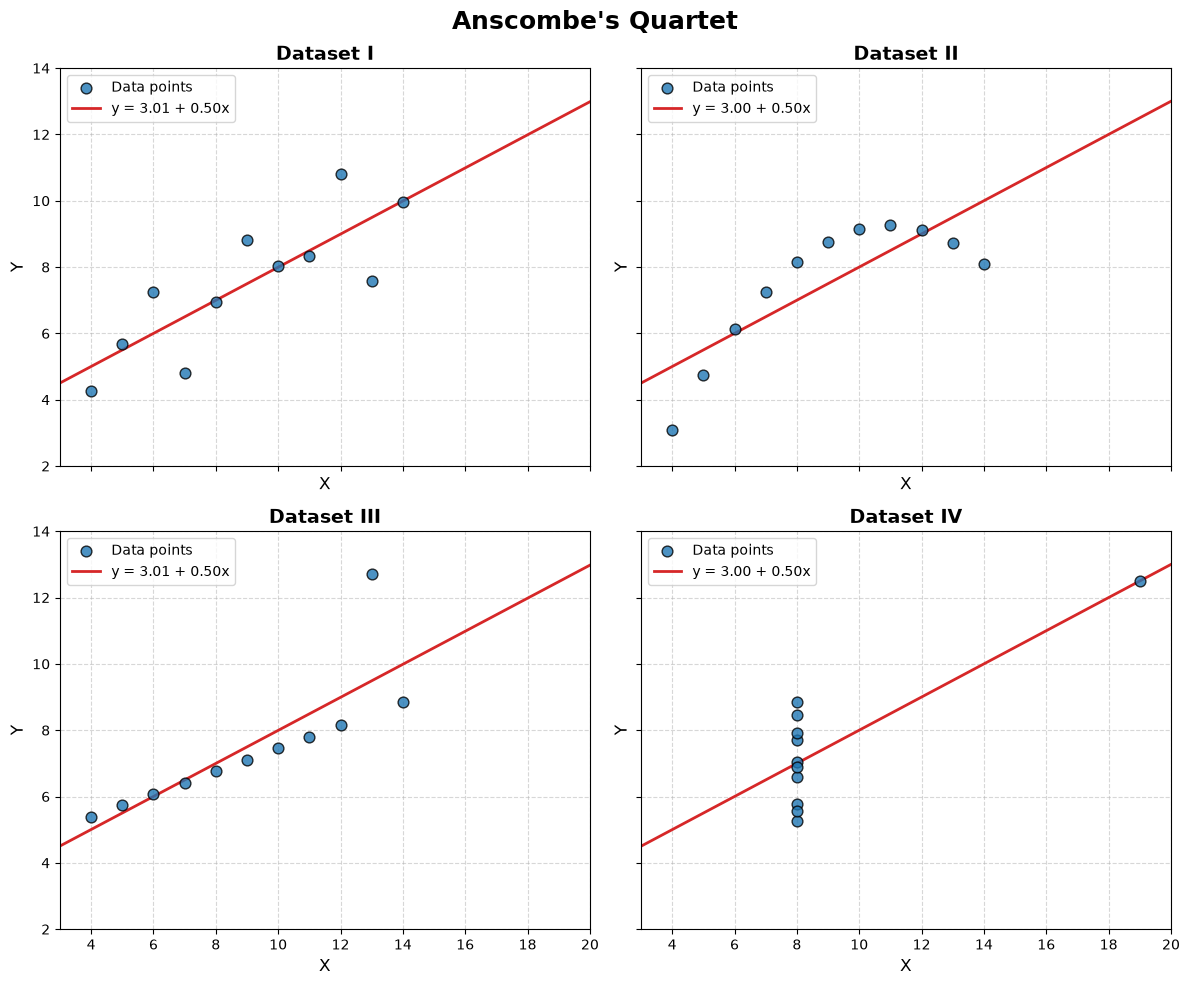

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. 建立安斯庫姆四分位圖的數據集
data = {
    "x1": [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
    "y1": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.8, 4.82, 5.68],
    "x2": [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
    "y2": [9.14, 8.14, 8.74, 8.77, 9.26, 8.1, 6.13, 3.1, 9.13, 7.26, 4.74],
    "x3": [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
    "y3": [7.46, 6.77, 12.7, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
    "x4": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
    "y4": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.5, 5.56, 7.91, 6.89],
}

# 2. 設定繪圖風格與畫布大小 (2x2 子圖)
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
fig.suptitle("Anscombe's Quartet", fontsize=18, fontweight="bold")

# 定義四組數據名稱與對應的子圖位置
datasets = [
    ("Dataset I", "x1", "y1", axes[0, 0]),
    ("Dataset II", "x2", "y2", axes[0, 1]),
    ("Dataset III", "x3", "y3", axes[1, 0]),
    ("Dataset IV", "x4", "y4", axes[1, 1]),
]

# 生成用於繪製迴歸線的 X 軸延伸範圍 (3 到 20)
x_range = np.linspace(3, 20, 100)

# 3. 逐一繪製每組數據
for title, x_col, y_col, ax in datasets:
    x = np.array(data[x_col])
    y = np.array(data[y_col])

    # 計算一階線性迴歸 (y = m*x + c)
    m, c = np.polyfit(x, y, deg=1)

    # 繪製資料點 (散布圖)
    ax.scatter(
        x,
        y,
        color="#1f77b4",
        s=60,
        alpha=0.8,
        edgecolors="k",
        zorder=3,
        label="Data points",
    )

    # 繪製迴歸線
    ax.plot(
        x_range,
        m * x_range + c,
        color="#d62728",
        linewidth=2,
        label=f"y = {c:.2f} + {m:.2f}x",
    )

    # 設定子圖標題與座標軸名稱
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("X", fontsize=12)
    ax.set_ylabel("Y", fontsize=12)
    ax.set_xlim(3, 20)
    ax.set_ylim(2, 14)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

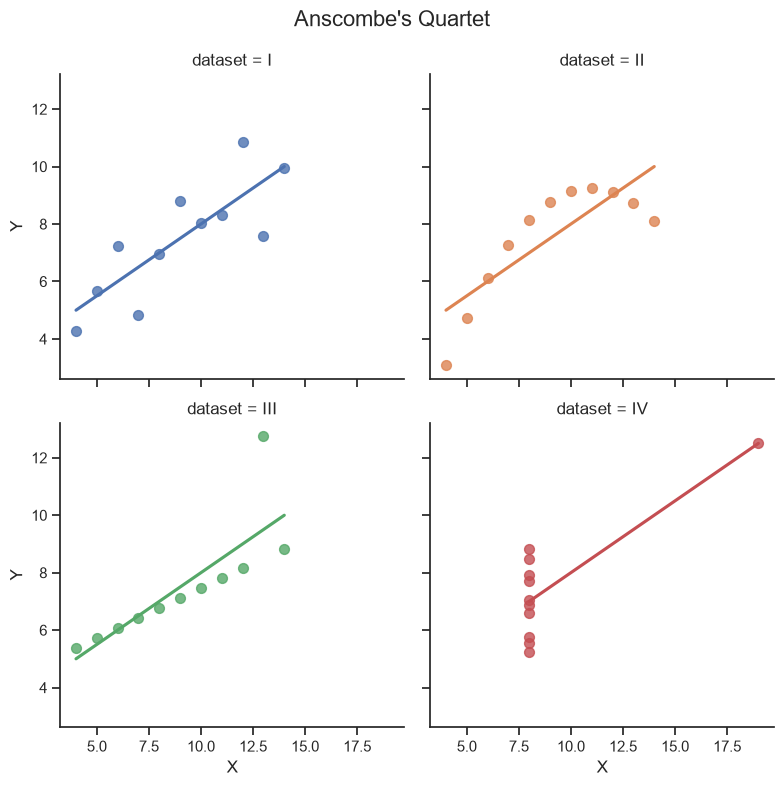

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 設定 Seaborn 主題風格
sns.set_theme(style="ticks")

# 載入 Seaborn 內建的 Anscombe 資料集
df = sns.load_dataset("anscombe")

# 使用 lmplot 一次繪製四組數據的散布圖與迴歸線
g = sns.lmplot(
    data=df,
    x="x",
    y="y",
    col="dataset",
    hue="dataset",
    col_wrap=2,
    ci=None,  # 不顯示置信區間
    height=4,
    scatter_kws={"s": 50, "alpha": 0.8},
)

g.set_axis_labels("X", "Y")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Anscombe's Quartet", fontsize=16)
plt.show()

In [ ]:
import numpy as np  # 匯入 NumPy 套件，用於高效的數值計算與陣列操作
import pandas as pd  # 匯入 Pandas 套件，用於資料處理與表格資料分析
import matplotlib.pyplot as plt  # 匯入 Matplotlib 的繪圖模組，用於基礎圖表繪製
import seaborn as sns  # 匯入 Seaborn 套件，用於繪製美觀的統計視覺化圖表
# Jupyter Notebook 的 Magic 指令：將圖表直接嵌入在筆記本單元格下方顯示
%matplotlib inline  

# 載入 autoreload 擴充功能，用於自動重新載入模組
%reload_ext autoreload  
# 設定 autoreload 模式 2：每次執行程式碼時，自動重新載入所有已修改的外掛模組
%autoreload 2  

In [ ]:
# 列出 Seaborn 官方目前內建支援的所有練習用資料集名稱
print(sns.get_dataset_names())  

# 載入內建的美國各州汽車肇事率統計資料集，並儲存為 crash_df
crash_df = sns.load_dataset('car_crashes')  
crash_df
# 使用 Pandas 讀取自訂的 CSV 資料集，並儲存為名為 cs_df 的 DataFrame
cs_df = pd.read_csv('ComputerSales.csv')  

In [ ]:
####Distribution Plot
# 使用 Seaborn 繪製單變數（not_distracted 欄位：未分心駕駛的車禍比例）的分佈圖
# crash_df['not_distracted']：指定要分析的單一欄位資料
# kde=False：關閉核密度估計曲線（KDE），僅顯示直方圖本體
# bins=25：將數據區間均等切割成 25 個計數箱（長條）
sns.distplot(crash_df['not_distracted'], kde=True, bins=25)
#sns.histplot(crash_df['not_distracted'], kde=False, bins=25)

In [ ]:
####Joint Plot

# 雙變數聯合分佈圖（jointplot）預設會比較兩種數據分佈，並繪製出散佈圖
# 從圖表中可以看出，當駕駛有超速傾向時，他們往往也較容易涉及酒後駕車
# 透過設定 kind='reg' 參數，可以在圖中加上線性迴歸擬合線
# 設定 kind='kde' 可以繪製出二維的核密度估計圖（等高線圖）
# 核密度估計（KDE）是一種用於估算數據連續分佈形狀的方法
# 設定 kind='hex' 可以繪製蜂巢圖（六角形分佈圖），適合用於展示高密度重疊數據

sns.jointplot(x='speeding', y='alcohol', data=crash_df, kind='reg')
# 繪製聯合分佈圖：
# x='speeding'：X 軸為超速相關數據
# y='alcohol'：Y 軸為酒駕相關數據
# data=crash_df：傳入的資料集來源
# kind='reg'：在主圖呈現散佈圖與線性迴歸趨勢線，頂端與右側則分別繪製兩變數的直方圖與擬合曲線 "kde","hex"

In [ ]:
###KDE Plot

In [ ]:
# 單獨繪製核密度估計圖（KDE Plot）

sns.kdeplot(crash_df['alcohol'])
# 使用 Seaborn 繪製 alcohol（酒駕比例）欄位的連續數據分佈曲線
# 核心作用：透過平滑的概率密度曲線，直觀展示數據在不同數值區間的集中程度與分佈型態

In [ ]:
### line plot
# Load dataset
# 載入 Seaborn 內建的小費（tips）資料集
data = sns.load_dataset('tips')


# 繪製折線圖：設定 X 軸為消費總金額（total_bill），Y 軸為小費金額（tip）
# 註：當同一個 X 軸數值包含多筆資料時，lineplot 預設會自動計算平均值並繪製藍色半透明的 95% 信賴區間
sns.lineplot(x='total_bill', y='tip', data=data)

# 為圖表加入標題
plt.title('Line Plot of Tip Over Total Bill')

# 顯現/印出最終繪製完成的圖表
plt.show()

In [ ]:
###Pair Plots
# 配對圖（Pair Plot）會自動繪製資料框中所有數值型欄位兩兩之間的關係圖
sns.pairplot(crash_df)
# 傳入 crash_df 資料集，產生一個圖表矩陣：
# 對角線上繪製各欄位自身的單變數分佈圖（預設為直方圖/KDE）
# 非對角線上繪製兩欄位之間的雙變數散佈圖（Scatter Plot）




In [ ]:
# 載入內建的小費（tips）資料集
tips_df = sns.load_dataset('tips')
tips_df
# 透過 hue 參數可以傳入類別型欄位（例如性別 sex），讓圖表依照類別自動上色區分
# 可以結合 Matplotlib 的配色調色盤（palette 參數）來自訂圖表的色彩套用風格
sns.pairplot(tips_df, hue='sex', palette='vlag')

In [ ]:
###Rug Plots
# 將陣列中單一欄位的每個資料點，以小刻度線（條線）的形式繪製在座標軸上
# 透過地毯圖（Rug Plot），在資料最常見、數值最集中的區域，你會看到線條分布得非常緊密
# 這原理類似於直方圖（Histogram）：數據越集中、出現頻率越高的地方，直方圖的長條就會越高等高

sns.rugplot(tips_df['tip'])
# 傳入小費資料集中的 'tip'（小費金額）欄位繪製地毯圖
# 效果：會在 X 軸底部呈現一條條垂直的小刻度線，每條線代表一個實際的資料數據點

In [ ]:
###Styling

# 你可以設定座標軸與背景網格的視覺風格
# white（白色背景）、darkgrid（灰色背景加白網格）、whitegrid（白色背景加灰網格）、dark（純灰背景）、ticks（白色背景帶座標軸刻度線）
sns.set_style('white')  # 設定圖表背景風格為純白色

# 可以直接調用 Matplotlib 的圖表尺寸設定功能
plt.figure(figsize=(8, 4))  # 設定圖表畫布寬度為 8 英吋、高度為 4 英吋

# 根據資料展示的情境（如論文 paper、簡報 talk、海報 poster），自動縮放標籤、線條與文字的大小
sns.set_context('paper', font_scale=1.4)  # 設定整體排版上下文為論文風格（paper），並將字體比例放大至 1.4 倍

sns.jointplot(x='speeding', y='alcohol', data=crash_df, kind='reg')
# 繪製聯合分佈圖：以超速（speeding）為 X 軸、酒駕（alcohol）為 Y 軸，並加上線性迴歸擬合線


# 移除圖表外框線（邊框 spines）
# 透過傳入 right=True、left=True、bottom=True、top=True 等參數，可以指定隱藏特定的邊框
sns.despine(left=False, bottom=False)
# 預設會自動移除上方（top）與右側（right）的外框線
# 此處明確指定 left=False 與 bottom=False，代表保留左側與底部的座標軸線

In [ ]:
###Bar Plots
# 著重於結合類別型數據與數值型欄位來觀察資料的分佈情況
# 根據特定的聚合函數（預設計算平均值 mean）來聚合類別數據
# 依據性別（sex）欄位來估算消費總金額（total_bill）
# 透過 estimator 參數，你可以改用平均值以外的其他統計函數
# 例如 NumPy 提供的：np.median（中位數）、np.std（標準差）、np.var（變異數）、np.cov（共變異數），甚至可以自訂函數

sns.barplot(x='sex', y='total_bill', data=tips_df, estimator=np.median, palette="muted")
# 繪製類別條形圖（Bar Plot）：
# x='sex'：X 軸傳入類別欄位（性別）
# y='total_bill'：Y 軸傳入要計算的數值欄位（總帳單金額）
# data=tips_df：指定使用的資料集
# estimator=np.median：將預設的計算平均值改為計算「中位數」（長條頂端高度代表中位數，長條上的黑線段為信賴區間估計）

In [ ]:
###Count Plot
# 計數圖（Count Plot）類似於條形圖（Bar Plot），但它的聚合函數固定為統計資料發生的「總次數（出現頻率）」

sns.countplot(x='sex', data=tips_df)
# 繪製類別計數圖：
# x='sex'：指定要統計的類別欄位（性別）
# data=tips_df：指定使用的資料集
# 效果：Y 軸會自動設為數據筆數（Count），分別顯示男性（Male）與女性（Female）在資料集中出現的總次數/人數

In [ ]:
###Box Plot
plt.figure(figsize=(14, 9))  # 設定圖表畫布尺寸為寬 14 英吋、高 9 英吋
sns.set_style('darkgrid')  # 設定圖表背景視覺風格為深色網格（darkgrid）

# 箱形圖（Box plot）能讓你比較不同變數之間的數據分佈
# 箱體顯示資料的四分位數。中間橫線代表中位數（Q2 / 50% 分位數），
# 箱體的上下邊界則分別代表第一四分位數（Q1 / 25%）與第三四分位數（Q3 / 75%），亦即四分位距（IQR）
# 箱鬍（Whiskers，延伸出去的線段）覆蓋除了離群值（Outliers）之外的所有數據範圍
# 超過箱鬍範圍的個別資料點則會被獨立繪製為離群值點
# 透過 hue 參數可以加入另一個分類維度（例如性別 sex）進行次級分組比較
# 從視覺化結果可以看出：男性在週五的消費金額明顯高於女性，但在週六的消費金額則低於女性

sns.boxplot(x='day', y='total_bill', data=tips_df, hue='sex')
# 繪製多維度箱形圖：
# x='day'：X 軸以星期幾（星期四至星期日）作為主要類別
# y='total_bill'：Y 軸呈現消費總金額（數值分佈）
# data=tips_df：指定使用的資料集
# hue='sex'：依性別（Male/Female）將每個星期的數據拆分成兩個獨立箱形圖進行比較

# 將圖例（Legend）自動放置在畫布中不易遮擋數據的最佳位置（loc=0 代表 'best'）
plt.legend(loc=0)

In [ ]:
###Violin Plot
# 小提琴圖（Violin Plot）是箱型圖（Box Plot）與核密度估計（KDE）的結合體
# 相較於箱型圖直接對應具體的數據分位點，小提琴圖透過核密度估計（KDE）來展示數據在不同數值區間的平滑機率密度分佈形狀（越寬代表數據越集中）
# 設定 split=True 可以將兩個 hue 類別（如男女）分別繪製在同一支小提琴的左右兩半，方便直接對比不同類別間的分佈差異

sns.violinplot(x='day', y='total_bill', data=tips_df, hue='sex', split=True)
# 繪製分裂式小提琴圖：
# x='day'：X 軸依星期進行分組
# y='total_bill'：Y 軸顯示消費總金額分佈
# data=tips_df：指定使用的資料集
# hue='sex'：依性別進行次級分類
# split=True：將同一個星期的男性與女性分佈合併為一支小提琴（左半邊為男性/右半邊為女性），節省空間且更易比較

In [ ]:
###Strip Plot
plt.figure(figsize=(8, 5))  # 設定圖表畫布寬度為 8 英吋、高度為 5 英吋
# 條狀圖/條線散佈圖（Strip Plot）會將所有實際數據點畫成散佈圖，其中一個變數為類別型資料
# 它常與箱形圖（Box Plot）疊加使用，在呈現整體分佈概況的同時展示所有真實觀察值
# jitter 參數可以將重疊的數據點在類別軸上隨機微幅晃開（加入雜訊），避免數據點完全重疊在一起而無法辨識數量
# 透過 hue 參數依性別（男/女）進一步將資料點上色區分
# dodge=True 會將不同的 hue 類別（男/女）在水平方向上分開繪製，而不是混在同一個垂直線上

sns.stripplot(x='day', y='total_bill', data=tips_df, jitter=True, 
              hue='sex', dodge=True)
# 繪製分裂式條線散佈圖：
# x='day'：X 軸指定星期幾作為主要類別
# y='total_bill'：Y 軸顯示消費總金額
# data=tips_df：指定傳入的小費資料集
# jitter=True：開啟資料點隨機抖動，防止點與點重疊
# hue='sex'：依性別欄位進行色彩分組
# dodge=True：將男性與女性的資料點左右分列開來，方便獨立比較各自的分佈

In [ ]:
###Swarm Plot
# 蜂群圖（Swarm Plot）類似於條線散佈圖（Strip Plot），但會自動調整資料點的位置以確保點與點之間不會互相重疊
# 它的視覺呈現效果看起來像是結合了小提琴圖（展現密度分佈形狀）與條線散佈圖（展現個別原始資料點）

# sns.swarmplot(x='day',y='total_bill',data=tips_df)

# 你可以將小提琴圖與蜂群圖疊加在同一個圖表中繪製，同時展現平滑密度分佈與個體數據點

sns.violinplot(x='day', y='total_bill', data=tips_df)
# 第一層：繪製小提琴圖作為底圖，呈現資料的總體分佈形狀與四分位數

sns.swarmplot(x='day', y='total_bill', data=tips_df, color='white')
# 第二層：在同一張圖上疊加白色點的蜂群圖
# color='white'：將資料點設為白色，使其在小提琴圖的背景色上能清晰對比呈現

In [ ]:
###Palettes
# 設定圖表畫布寬度為 8 英吋、高度為 6 英吋
plt.figure(figsize=(8, 6))  
# 設定圖表背景風格為深色（dark）無網格模式
sns.set_style('dark')  
 # 設定視覺風格縮放比例為「簡報/演講（talk）」模式，標籤與線條會自動放大以利投影片展示
sns.set_context('talk') 


# 你可以使用 Matplotlib 提供的各式調色盤（Color Maps）來進行圖表色彩的風格設定
# https://matplotlib.org/3.3.1/tutorials/colors/colormaps.html
sns.stripplot(x='day', y='total_bill', data=tips_df, hue='sex', 
              palette='seismic')
# 繪製條線散佈圖（Strip Plot）：
# x='day'：X 軸以星期幾作為類別分類
# y='total_bill'：Y 軸顯示消費總金額
# data=tips_df：指定使用的資料集
# hue='sex'：依性別欄位區分資料點顏色
# palette='seismic'：套用 Matplotlib 的 'seismic' 漸層配色調色盘（以冷色/暖色對比呈現不同性別）


# https://matplotlib.org/3.3.1/api/_as_gen/matplotlib.pyplot.legend.html)
# 新增可選的圖例說明，可傳入位置代碼數字（0: 自動最佳位置 best, 1: 右上角, 2: 左上角, 3: 左下角, 4: 右下角）
# 或者也可以傳入一個包含 (x, y) 座標的元組（Tuple），以畫布左下角為基準來指定圖例的精確擺放位置
plt.legend(loc=0)
# 將圖例自動放置在畫布中最適當（不易遮擋數據）的位置

In [ ]:
###Subplot
plt.figure(figsize=(8, 6))  # 設定圖表畫布寬度為 8 英吋、高度為 6 英吋
sns.set_context('paper', font_scale=1.4)  # 設定視覺風格為「論文 (paper)」格式，並將字體比例放大 1.4 倍
data = sns.load_dataset('tips')

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.scatterplot(x='total_bill', y='tip', data=data)
plt.title('Scatter Plot of Total Bill vs Tip')

plt.subplot(2, 2, 2)
sns.boxplot(x='day', y='total_bill', data=data)
plt.title('Box Plot of Total Bill by Day')

plt.subplot(2, 2, 3)
sns.barplot(x='day', y='total_bill', data=data)
plt.title('Bar Plot of Total Bill by Day')

plt.subplot(2, 2, 4)
sns.histplot(data['total_bill'], kde=True)
plt.title('Histogram of Total Bill')

plt.tight_layout()
plt.show()

In [ ]:
###Heatmaps
#資料（Data）：   
#兩個類別屬性（Two categorical attributes）(x, y)   
#一個定量屬性（One quantitative attribute）(value/數值) 

plt.figure(figsize=(8, 6))  # 設定圖表畫布寬度為 8 英吋、高度為 6 英吋
sns.set_context('paper', font_scale=1.4)  # 設定視覺風格為「論文 (paper)」格式，並將字體比例放大 1.4 倍

# 要使用數據建立熱力圖（Heatmap），必須先將資料整理成矩陣（Matrix）格式，亦即欄位與橫列均代表數據變數
# 相關係數（Correlation）可以用來評估特定變數對結果的影響力高低
# 由此分析可以看出：過往肇事紀錄（no_previous）與整體車禍事故率呈現高度相關，而保費（ins_premium）的相關性則較低

crash_mx = crash_df.corr(numeric_only=True)
# 計算 crash_df 資料集中所有數值型欄位兩兩之間的皮爾森相關係數（Pearson correlation matrix），並將結果矩陣存入 crash_mx

# 建立熱力圖，啟用數值標註並設定調色盤風格
sns.heatmap(crash_mx, annot=True, cmap='Blues')
# 繪製熱力圖：
# crash_mx：傳入相關係數矩陣
# annot=True：在熱力圖每個格子內顯示具體的相關係數數值標註
# cmap='Blues'：設定色調風格為單色藍色漸層（數值越大/相關性越高，顏色越深）

In [ ]:
plt.figure(figsize=(8, 6))  # 設定圖表畫布寬度為 8 英吋、高度為 6 英吋
sns.set_context('paper', font_scale=1.4)  # 設定視覺風格為「論文 (paper)」格式，並將字體放大 1.4 倍以利閱讀

# 我們可以建立一個樞紐矩陣：以月份（month）作為索引列、年份（year）作為欄位，矩陣內部的數值則代表對應的乘客數量
# 從視覺化熱力圖中可以看出：隨著時間推移（年份增加），航班乘客人數整體呈成長趨勢；且每年搭機旅遊的高峰期集中在 7 月與 8 月

flights = sns.load_dataset("flights")
# 載入 Seaborn 內建的經典航班乘客數據集（flights）

flights = flights.pivot_table(index='month', columns='year', values='passengers')
# 將長表格結構重塑（Pivot）為交叉二維矩陣：
# index='month'：縱軸（橫列）為 1~12 月
# columns='year'：橫軸（欄位）為各年份
# values='passengers'：格子填入乘客總人數

# 透過設定分隔線參數，可以讓熱力圖中每個格子之間的區隔更加清晰

sns.heatmap(flights, cmap='Blues', linecolor='white', linewidth=1)
# 繪製矩陣熱力圖：
# flights：傳入重塑後的樞紐數據矩陣
# cmap='Blues'：套用藍色漸層配色（乘客數越多/數值越大，藍色越深）
# linecolor='white'：設定網格分隔線的顏色為白色
# linewidth=1：設定網格分隔線的寬度為 1 像素

In [ ]:
###Cluster Map
plt.figure(figsize=(8, 6))  # 設定圖表畫布寬度為 8 英吋、高度為 6 英吋
sns.set_context('paper', font_scale=1.4)  # 設定視覺風格為「論文 (paper)」格式，並將字體比例放大 1.4 倍


# 階層樹狀分群圖（Cluster map）是一種結合了「階層式分群（Hierarchical Clustering）」與「熱力圖（Heatmap）」的高階圖表
# 它的計算原理為：計算資料點之間的距離（相似度），將距離最近的合併為同一群，並不斷重複此步驟
# （此演算法會同時對熱力圖的「橫列 (Rows)」與「直欄 (Columns)」進行相似性比較與重新排序）

iris = sns.load_dataset("iris")
# 載入內建的鳶尾花資料集
# 取出並移除 species（物種類別）欄位，因為分群計算只能處理純數值型資料
species = iris.pop("species")
sns.clustermap(iris)



In [ ]:
# 換回套用先前的航班資料集（flights）：可以看到年份與月份已經被重新排列（非原本的時間順序），將模式相似的資料聚合在一起
# 從分群樹狀圖中可以清楚觀察到：1959 年與 1960 年的 7 月及 8 月因為搭機人數趨勢非常接近，被自動歸類在同一個分群（Cluster）中

# standard_scale 參數可以用來對資料進行標準化/正規化處理（0 代表按列縮放，1 代表按欄縮放），消除極端數值的影響，使分析焦點集中在「分群模式」上

sns.clustermap(flights, cmap="Blues", standard_scale=1)
# 繪製階層樹狀集群圖：
# flights：傳入二維樞紐矩陣資料
# cmap="Blues"：套用藍色漸層配色
# standard_scale=1：對每一欄（Columns，即各年份）進行 0 到 1 之間的標準化縮放，以便在相同基準下比較不同月份的型態特徵

In [ ]:
###PairGrid
plt.figure(figsize=(8, 6))  # 設定圖表畫布寬度為 8 英吋、高度為 6 英吋
sns.set_context('paper', font_scale=1.4)  # 設定視覺風格為「論文 (paper)」格式，並將字體放大 1.4 倍
# 你可以建立自訂圖表網格（Grid），完全掌控要在每個圖格中顯示什麼類型的圖表
# 使用提供的資料集建立空白的 PairGrid 網格系統，並依據物種（species）欄位區分顏色
iris = sns.load_dataset("iris")
iris_g = sns.PairGrid(iris, hue="species")

# 在對角線、上方與下方的所有圖格中統一畫上散佈圖（Scatter plot）
iris_g.map(plt.scatter)

# 指定只在主對角線上繪製直方圖（Histogram），用來展示單一欄位自身的數據分佈
iris_g.map_diag(plt.hist)

# 在除了主對角線之外的所有其他位置（非對角線）繪製散佈圖
iris_g.map_offdiag(plt.scatter)

# 靈活設定不同區域的圖表型態：主對角線上方繪製散佈圖，主對角線下方繪製核密度估計圖（KDE plot）
iris_g.map_upper(plt.scatter)
iris_g.map_lower(sns.kdeplot)


In [ ]:

# 你也可以透過指定 x_vars 與 y_vars，只針對特定的 X 軸與 Y 軸變數組合建立自訂的矩陣網格
iris_g = sns.PairGrid(iris, hue="species",
                      x_vars=["sepal_length", "sepal_width"],
                      y_vars=["petal_length", "petal_width"])
# 建立靈活對配圖網格（PairGrid）：
# iris：使用的資料集
# hue="species"：依照物種進行顏色區分與視覺化分類
# x_vars：X 軸只選擇花萼長度（sepal_length）與花萼寬度（sepal_width）
# y_vars：Y 軸只選擇花瓣長度（petal_length）與花瓣寬度（petal_width）

iris_g.map(plt.scatter)
# 將 Matplotlib 的散佈圖（plt.scatter）套用到 PairGrid 網格內部的所有 2x2 子圖格中

# 最後為整個圖表矩陣加上圖例說明（標示不同 species 的對應顏色）
iris_g.add_legend()

In [ ]:
###Facet Grid
# 在網格中繪製多個子圖，並完全定義欄（columns）與列（rows）的拆解結構
# 取得吸菸者與非吸菸者在午餐及晚餐的消費總金額（total_bill）直方圖分佈
tips_fg = sns.FacetGrid(tips_df, col='time', row='smoker')

# 為直方圖（histogram）傳入額外的控制參數（如長條區間數 bins=8）
tips_fg.map(plt.hist, "total_bill", bins=8)

# 建立消費總金額（total_bill）與小費（tip）關係的散佈圖（因為是雙變數散佈圖，需要傳入兩個變數名稱）
tips_fg.map(plt.scatter, "total_bill", "tip")

# 將變數賦予不同的顏色，並調大網格子圖的尺寸
# 可以透過 col_order 改變欄位的顯示順序
# palette 參數用來指定所使用的色彩調色盤
tips_fg = sns.FacetGrid(tips_df, col='time', hue='smoker', height=4, aspect=1.3,
                       col_order=['Dinner', 'Lunch'], palette='Set1')
tips_fg.map(plt.scatter, "total_bill", "tip", edgecolor='w')


# 使用字典定義點標記（markers）的大小 (s=50)、外框線寬度 (.5) 與外框線顏色為白色 ("w")
kws = dict(s=50, linewidth=.5, edgecolor="w")

# 定義為吸菸者與非吸菸者指派不同的點形狀標記（如向上與向下的三角形）
tips_fg = sns.FacetGrid(tips_df, col='sex', hue='smoker', height=4, aspect=1.3,
                        hue_order=['Yes','No'], 
                        hue_kws=dict(marker=['^', 'v']))
tips_fg.map(plt.scatter, "total_bill", "tip", **kws)
tips_fg.add_legend()

# 這個資料集提供了不同受試者在測試期間的專注度等級與對應得分數據
att_df = sns.load_dataset("attention")  # 載入 Seaborn 內建的專注度實驗數據集（attention）

# 將每個受試者（subject）獨立繪製在各自的子圖中，每行最多擺放 5 張圖（col_wrap=5），並畫出他們的解題表現與分數
att_fg = sns.FacetGrid(att_df, col='subject', col_wrap=5, height=1.5)
# 建立網格框架：
# col='subject'：依受試者編號拆分欄位
# col_wrap=5：當欄位超過 5 個時自動換行繪製（防止圖表擠在同一行）
# height=1.5：每個獨立子圖的高度設為 1.5 英吋

att_fg.map(plt.plot, 'solutions', 'score', marker='.')
# 將折線圖（plt.plot）映射到網格上：
# 'solutions' 作為 X 軸（解題數），'score' 作為 Y 軸（得分）
# marker='.' 代表在折線圖的每個數據點上加上點狀標記

In [ ]:
###Regression Plots
# lmplot() 將線性迴歸圖（Regression Plot）與多圖格網格（FacetGrid）結合在一起
# 讓你能夠輕鬆地在跨類別的子圖矩陣中，同時繪製數據點與對應的線性迴歸擬合線

tips_df = sns.load_dataset('tips')
# 載入 Seaborn 內建的小費資料集（tips）並存入 tips_df

tips_df.head()
# 顯示 tips_df 資料集的前 5 筆資料，方便預覽欄位結構與數據內容


In [ ]:
plt.figure(figsize=(8,6))
sns.set_context('paper', font_scale=1.4)

plt.figure(figsize=(8,6))
# 我們可以繪製線性迴歸圖，用來探討消費總金額（total_bill）是否會影響小費金額（tip）
# hue 參數用來根據類別型資料（如性別 sex）將數據上色進行區分
# 從迴歸線趨勢可以看出：隨著帳單金額增加，男性給予的小費傾向比女性稍微多一些
# 為男性與女性分別定義不同的數據點形狀標記（如 'o' 代表圓圈，'^' 代表三角形）
# 可以透過傳入字典（Dictionary）格式給 scatter_kws，來控制散佈圖中數據點的樣式細節

sns.lmplot(
    x='total_bill', 
    y='tip', 
    hue='sex', 
    data=tips_df, 
    markers=['o', '^'], 
    scatter_kws={'s': 100, 'linewidths': 0.5, 'edgecolor': 'w'}  # 改用 linewidths
)
# 繪製結合迴歸分析與分類說明的 lmplot：
# x='total_bill'：X 軸為消費總金額
# y='tip'：Y 軸為小費金額
# hue='sex'：依性別分為兩組數據並畫出各自的迴歸擬合線
# data=tips_df：使用的資料集來源
# markers=['o', '^']：指定男性與女性在圖上的資料點符號形狀
# scatter_kws={'s': 100, 'linewidth': 0.5, 'edgecolor': 'w'}：
#   傳遞給底層散佈圖的樣式參數——點的大小為 100 (s=100)、外框線寬度為 0.5、外框線顏色為白色 ('w')

In [ ]:
# 將數據依據日期（day）或特定變數欄位，拆分到不同的直欄（Columns）子圖中繪製
sns.lmplot(x='total_bill', y='tip', col='sex', row='time', data=tips_df)


tips_df.head()
# 預覽 tips_df 資料集的前 5 筆資料

# 設定視覺風格為「海報（poster）」模式，並將字體比例放大 1.4 倍，使圖表中的文字與標籤更加清晰易讀
sns.set_context('poster', font_scale=1.4)


In [ ]:
sns.lmplot(x='total_bill', y='tip', data=tips_df, col='day', hue='sex',
          height=8, aspect=0.6)
# 繪製多子圖線性迴歸圖：
# x='total_bill'：X 軸為消費總金額
# y='tip'：Y 軸為小費金額
# data=tips_df：使用的資料集
# col='day'：依照星期幾（Thur, Fri, Sat, Sun）將資料拆分成 4 個獨立的欄位子圖
# hue='sex'：在每個子圖中，再依據性別（Male/Female）區分點的色彩並各自擬合迴歸線
# height=8：設定每個子圖的高度為 8 英吋
# aspect=0.6：設定每個子圖的寬高比為 0.6（寬度 = 8 * 0.6 = 4.8 英吋），使子圖呈高瘦型排列

In [ ]:
# proportional area : 用「堆疊長條圖 + 巢狀比例圓」呈現各組佔比

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---- 1. 建立假資料 ----
np.random.seed(42)  # 固定隨機種子，確保每次執行結果相同
v1 = np.random.randint(5, 45, 50)    # 產生 50 個 5~44 的隨機整數，代表 v1 組
v2 = np.random.randint(10, 60, 50)   # 產生 50 個 10~59 的隨機整數，代表 v2 組
v3 = np.random.randint(30, 80, 50)   # 產生 50 個 30~79 的隨機整數，代表 v3 組
v4 = np.random.randint(90, 100, 50)  # 產生 50 個 90~99 的隨機整數，代表 v4 組

# 把四組資料合併成 DataFrame，欄位為 v1, v2, v3, v4
df = pd.DataFrame(zip(v1, v2, v3, v4),
                  columns=['v1', 'v2', 'v3', 'v4'])
# 轉成 long format：兩欄 variable(組別), value(數值)，方便後續 groupby
df = df.melt()
#df.head()

# ---- 2. 計算每組總和與百分比 ----
v_list = ['v1', 'v2', 'v3', 'v4']  # 組別名稱
c_code = ['#F77F00', '#56C596', '#2A639B', '#F6D55C']  # 每組指定的顏色
dict_color = dict(zip(v_list, c_code))  # 組別 -> 顏色 的對照字典 (後面沒用到，但可供查詢)

# 依組別加總
df_gb = df.groupby(by='variable').sum().reset_index()
# 計算佔比(%)，保留到小數第 1 位
df_gb['pct'] = [round(i, 1) for i in df_gb['value']*100/df_gb['value'].sum()]
# 指定每組顏色
df_gb['color'] = c_code
df_gb

# ---- 3. 圖一：100% 堆疊長條圖 ----
groups = ['V']  # 只有一個 x 類別，所以會畫出一條長條
v1 = [df_gb.pct[0]]  # 取出 v1 的百分比
v2 = [df_gb.pct[1]]  # 取出 v2 的百分比
v3 = [df_gb.pct[2]]  # 取出 v3 的百分比
v4 = [df_gb.pct[3]]  # 取出 v4 的百分比
values = np.array([v1, v2, v3, v4])  # 整理成 (4,1) 陣列，方便用 bottom 堆疊

sns.set_style('darkgrid')  # 設定 seaborn 背景風格
fig, ax = plt.subplots(figsize=(1, 6))  # 建立細長的圖，適合顯示單一堆疊長條

# 逐層畫堆疊長條：bottom = 下面所有層的高度總和
for i, c in zip(range(values.shape[0]), df_gb.color):
    ax.bar(groups, values[i], bottom=np.sum(values[:i], axis=0), color=c)
plt.show()

# ---- 4. 圖二：巢狀比例圓 (面積代表佔比) ----
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(0, 0)  # 畫一個點，確保座標軸正常初始化
# 畫底圖：半徑為 1 的淺灰色大圓，代表 100%
cir = plt.Circle((0, 0), 1, color='lightgray', fill=True)
ax.add_patch(cir)

# 由大到小排序，這樣小圓才會蓋在大圓上面，形成巢狀效果
df_gb.sort_values(by=['pct'], ascending=False, inplace=True)

# 逐組畫比例圓
for i, c, l in zip(df_gb.pct, df_gb.color, df_gb.variable):
    data = np.array(i)  # 該組百分比
    # 用面積比例換算半徑： (πr^2)/(π*1^2) = pct/100，所以 r = sqrt(pct/100)
    r = np.sqrt(data/100)
    # 圓心放在 (0, r-1)，讓每個圓的「底部」都切齊在 y=-1，形成由下往上包覆的巢狀圓
    cir_p = plt.Circle((0, r-1), r, color=c, fill=True)
    ax.add_patch(cir_p)
    ax.axis('off')  # 關閉座標軸
    # 設定圓內文字樣式：白色、置中
    kw = dict(color="white", va="center", ha="center")
    kw.update(dict(fontsize=19))
    # 在圓頂部附近標示「組別 + 百分比」，2*r-1 是圓頂，-0.08 稍微往下偏移避免貼邊
    ax.text(0, (2*r)-1.08, l+' '+str(i)+'%', **kw)
    ax.set_aspect('equal')  # 等比例，避免圓被壓扁

plt.xlim([-1, 1])
plt.ylim([-1, 1])  
plt.show()

In [ ]:
# Pie chart : 用 plotly.express 畫圓餅圖

import plotly.express as px  # 載入 plotly 快速繪圖模組

# 建立圓餅圖
# df_gb : 前面 groupby 加總後的表格，包含 variable(組別)、value(總和)
# values='value' : 用 value 欄決定每塊扇形的大小比例
# names='variable' : 用 variable 欄作為每塊扇形的標籤
# color='variable' : 依組別上色
# color_discrete_map=dict_color : 使用自訂的組別->顏色對照字典 (v1~v4 對應 #F77F00 等)
fig = px.pie(df_gb, values='value', names='variable',
             color='variable', color_discrete_map=dict_color)

# 調整版面：圖寬高 600x600，四邊留白(margin)都設為 0，讓圓餅圖置中填滿
fig.update_layout(width=600, height=600, margin=dict(l=0, r=0, b=0, t=0))

fig.show()  # 顯示互動式圖表

In [ ]:
# Donut chart : 甜甜圈圖，本質是中間挖洞的圓餅圖

# 建立甜甜圈圖
# df_gb : 前面 groupby 加總後的表格，包含 variable(組別)、value(總和)
# values='value' : 用 value 欄決定每塊扇形的大小比例
# names='variable' : 用 variable 欄作為每塊扇形的標籤
# color='variable' : 依組別上色
# color_discrete_map=dict_color : 使用自訂的組別->顏色對照字典
# hole=0.6 : 中間挖洞，0 為圓餅圖，值越大洞越大(0~1)，0.6 表示洞半徑為全圓的 60%
fig = px.pie(df_gb, values='value', names='variable',
             color='variable', color_discrete_map=dict_color,
             hole=0.6)

# 調整版面：圖寬高 600x600，四邊留白(margin)都設為 0，讓圖形置中填滿
fig.update_layout(width=600, height=600, margin=dict(l=0, r=0, b=0, t=0))

fig.show()

In [ ]:
# Radial bar chart
plt.figure(figsize=(8,8))  # 建立 8x8 的圖
ax = plt.subplot(111, polar=True)  # 建立極座標子圖，111 表示 1x1 網格第 1 個
plt.axis()  # 顯示座標軸

# ---- 1. 建立假資料 ----
np.random.seed(42)  # 固定隨機種子，確保結果可重現
v1 = np.random.randint(5,50,50)    # v1 組：5~49 的 50 個隨機數
v2 = np.random.randint(5,50,50)    # v2 組：同上
v3 = np.random.randint(20,60,50)   # v3 組：20~59 的 50 個隨機數
v4 = np.random.randint(20,60,50)   # v4 組：同上
v5 = np.random.randint(90,100,50)  # v5 組：90~99 的 50 個隨機數，數值最大
v6 = np.random.randint(10,50,50)   # v6~v9 皆為不同範圍的隨機數
v7 = np.random.randint(10,50,50)
v8 = np.random.randint(25,60,50)
v9 = np.random.randint(25,60,50)

# 合併成 DataFrame，欄位為 v1~v9
df = pd.DataFrame(zip(v1,v2,v3,v4,v5,v6,v7,v8,v9),
                  columns=['v1','v2','v3','v4','v5','v6','v7','v8','v9'])
df = df.melt()  # 轉成 long format：variable(組別)、value(數值) 兩欄

# 取出 seaborn 的 Spectral 調色盤，共 9 色，轉成 HEX 字串供 matplotlib 使用
pal = list(sns.color_palette(palette='Spectral', n_colors=9).as_hex())

# 依組別加總，並計算佔比(%)到小數第 1 位
df_gb = df.groupby(by='variable').sum().reset_index()
df_gb['pct']= [round(i,1) for i in df_gb['value']*100/df_gb['value'].sum()]
df_gb['color']= pal  # 指定每組顏色
df_gb

# ---- 2. 設定極座標範圍與顏色 ----
# 設定半徑(長條高度)範圍 0~25，因為 pct 約在 7%~15% 之間，留白讓標籤有空間
ax.axis(ymin=0, ymax=25)
# 再次取出調色盤 (與上面重複，可刪掉其中一個)
pal = list(sns.color_palette(palette='Spectral', n_colors=9).as_hex())

# ---- 3. 計算每根長條的位置與寬度 ----
heights = df_gb['pct']  # 長條高度 = 佔比
width = 2*np.pi / len(df_gb)  # 每根寬度 = 圓周 2π 除以組數，9 組剛好繞一圈
# 每根長條的中心角度：1*width, 2*width, ... 9*width
indexes = list(range(1, len(df_gb)+1))
angles = [element * width for element in indexes]

# 在極座標上畫長條：x=角度，height=半徑高度，bottom=0 從圓心開始
# edgecolor="white" 讓每根之間有白色間隔
bars = ax.bar(x=angles, height=heights, width=width, bottom=0,
              linewidth=1, edgecolor="white", color=pal)

# ---- 4. 加上標籤 ----
labelPadding = 2  # 標籤與長條頂端的距離

# 組合標籤文字，例如 "v1 8.5%"
labels = [i+' '+str(j)+'%' for i,j in zip(df_gb.variable, df_gb.pct)]

for bar, angle, height, label in zip(bars, angles, heights, labels):
    rotation = np.rad2deg(angle)  # 把弧度轉成角度，用來旋轉文字
    alignment = ""
    # 處理左右半圈的文字方向，避免文字上下顛倒：
    # 左半圓(90~270度) 文字靠右對齊並轉 180 度，右半圓則靠左對齊
    if angle >= np.pi/2 and angle < 3*np.pi/2:
        alignment = "right"
        rotation = rotation + 180
    else: 
        alignment = "left"

    # 在長條頂端外側加上標籤
    ax.text(x=angle, y=0 + bar.get_height() + labelPadding,
            s=label, ha=alignment, va='center', rotation=rotation, 
            rotation_mode="anchor", fontsize=12)
    
    # 清除預設的角度刻度標籤，只留乾淨的放射狀圖形
    ax.set_thetagrids([], labels=[])

plt.show()  # 顯示圖形

In [ ]:
#Circular Barplot

# 建立測試資料：50 個項目，Name 為 item 1~50，Value 為 10~99 隨機數
df = pd.DataFrame(
        {
            'Name': ['item ' + str(i) for i in list(range(1, 51)) ],
            'Value': np.random.randint(low=10, high=100, size=50)
        })

# 顯示前 3 列，確認資料格式
df.head(3)

# 設定圖形大小
plt.figure(figsize=(20,10))

# 建立極座標子圖，111 表示 1x1 網格第 1 個，polar=True 改為圓形座標
ax = plt.subplot(111, polar=True)

# 關閉格線與座標軸，讓圖形更乾淨
plt.axis('off')

# 設定半徑(座標)的上下限：
# lowerLimit=30 讓圓心留白形成中空圓，upperLimit=100 為最外圈
upperLimit = 100
lowerLimit = 30

# 取出資料中的最大值，作為高度換算的基準
max = df['Value'].max()

# 計算每根長條的高度：把原始 Value 線性映射到 [lowerLimit, upperLimit]
# 概念：0 會對應到 lowerLimit(圓心鏤空處)，最大值會對應到 upperLimit(最外圈)
# slope 為縮放斜率，heights 為轉換後的半徑高度
slope = (max - lowerLimit) / max
heights = slope * df.Value + lowerLimit

# 計算每根長條的寬度：圓周 2π 除以資料筆數，50 根剛好繞一圈
width = 2*np.pi / len(df.index)

# 計算每根長條的中心角度：1*width, 2*width, ... 50*width
indexes = list(range(1, len(df.index)+1))
angles = [element * width for element in indexes]
angles

# 畫出長條：
# x=角度，height=高度，width=寬度
# bottom=lowerLimit 表示從半徑 30 開始往外畫，所以中間會有半徑 30 的空洞
# edgecolor="white" 讓每根之間有白色間隔
bars = ax.bar(
    x=angles, 
    height=heights, 
    width=width, 
    bottom=lowerLimit,
    linewidth=2, 
    edgecolor="white")


In [ ]:
# initialize the figure
# Circular barplot ：重畫圖形 + 加上旋轉標籤

# 初始化圖形：20x10 大圖 + 極座標子圖
plt.figure(figsize=(20,10))
ax = plt.subplot(111, polar=True)  # 111 表示 1x1 網格第 1 個，polar=True 用圓形座標
plt.axis('off')  # 關閉格線與座標軸，讓圖更乾淨

# 畫出長條：
# x=角度，height=高度(前面換算好的 heights)，width=每根寬度
# bottom=lowerLimit 從半徑 30 開始往外畫，中間留白形成中空圓
# color="#61a4b2" 統一用藍綠色，edgecolor="white" 讓每根有白色間隔
bars = ax.bar(
    x=angles, 
    height=heights, 
    width=width, 
    bottom=lowerLimit,
    linewidth=2, 
    edgecolor="white",
    color="#61a4b2",
)

# 標籤與長條頂端的距離，避免文字貼著長條
labelPadding = 4

# 逐根加上項目名稱標籤
for bar, angle, height, label in zip(bars, angles, heights, df["Name"]):

    # 標籤要跟著角度旋轉，matplotlib 的 rotation 要用「角度制」，所以用 rad2deg 轉換
    rotation = np.rad2deg(angle)

    # 翻轉左半圈的標籤，避免文字上下顛倒：
    # 左半圓(90~270度) 文字靠右對齊並多轉 180 度，右半圓則靠左對齊
    alignment = ""
    if angle >= np.pi/2 and angle < 3*np.pi/2:
        alignment = "right"
        rotation = rotation + 180
    else: 
        alignment = "left"

    # 在長條頂端外側加上文字
    # y = 起點 lowerLimit + 長條高度 + 留白，即為文字的半徑位置
    # rotation_mode="anchor" 讓旋轉以對齊點為中心，文字才不會跑掉
    ax.text(
        x=angle, 
        y=lowerLimit + bar.get_height() + labelPadding, 
        s=label,  # 標籤內容：item 1~50
        ha=alignment, 
        va='center', 
        rotation=rotation, 
        rotation_mode="anchor",
        fontsize=12)

In [ ]:
# Radar chart

import plotly.express as px  # 載入 plotly 快速繪圖模組
import pandas as pd  # 載入 pandas (此段沒直接用到，但通常搭配 df_gb 使用)
# 用前面算好的 df_gb 畫雷達圖
# r='pct' : 半徑方向為佔比，數值越大點離圓心越遠
# theta='variable' : 角度方向為組別 v1~v4，平均分配在圓周上
# line_close=True : 首尾相連，形成封閉多邊形
# color_discrete_sequence=[c_code[1]] : 指定線條顏色，取 c_code 第 2 個顏色('#56C596')
fig = px.line_polar(df_gb, r='pct', theta='variable',
                    line_close=True, color_discrete_sequence=[c_code[1]])

# 設定半徑軸範圍 0~25，因為 pct 約在 10%~40% 之間，固定範圍方便比較
fig.update_polars(radialaxis_range=[0,25])

# 調整版面：600x600，四邊小留白，上方多留 20 給標題空間
fig.update_layout(width=600, height=600, margin=dict(l=10,r=10,b=10,t=20))

# 將折線圍起來的區域填滿顏色，變成實心雷達圖；若拿掉此行則只剩框線
fig.update_traces(fill='toself')

fig.show()  # 顯示互動式圖表

In [ ]:
#Circos Plot
from pycirclize import Circos  # 載入 Circos 環形圖套件
import numpy as np
np.random.seed(0)  # 固定隨機種子，確保隨機產生的 y 值可重現

# 初始化環形扇區：定義 5 個扇區 A~E，數字為各扇區的弧長(比例)
# space=5 為扇區之間的間隔角度
sectors = {"A": 10, "B": 15, "C": 12, "D": 20, "E": 15}
circos = Circos(sectors, space=5)

for sector in circos.sectors:  # 逐一處理每個扇區
    # 在半徑 r=110 外圈標示扇區名稱
    sector.text(f"Sector: {sector.name}", r=110, size=15)
    # 建立 x 座標(扇區範圍內每 1 單位一點，+0.5 置中) 與隨機 y 值(0~99)
    x = np.arange(sector.start, sector.end) + 0.5
    y = np.random.randint(0, 100, len(x))
    # 第 1 軌道(外圈)：半徑 80~100，畫折線圖
    # r_pad_ratio=0.1 為軌道內外留白比例
    track1 = sector.add_track((80, 100), r_pad_ratio=0.1)
    track1.xticks_by_interval(interval=1)  # 每 1 單位畫一個刻度
    track1.axis()  # 畫出軌道邊框/軸線
    track1.line(x, y)  # 畫折線
    # 第 2 軌道(中圈)：半徑 55~75，畫散點圖
    track2 = sector.add_track((55, 75), r_pad_ratio=0.1)
    track2.axis()
    track2.scatter(x, y)  # 畫散點
    # 第 3 軌道(內圈)：半徑 30~50，畫長條圖
    track3 = sector.add_track((30, 50), r_pad_ratio=0.1)
    track3.axis()
    track3.bar(x, y)  # 畫長條

# 畫扇區之間的連結帶(link)：格式為 (扇區名, 起點, 終點)
circos.link(("A", 0, 3), ("B", 15, 12))  # A 的 0~3 連到 B 的 15~12，使用預設顏色
circos.link(("B", 0, 3), ("C", 7, 11), color="skyblue")  # B-C 連結，天空藍
circos.link(("C", 2, 5), ("E", 15, 12), color="chocolate", direction=1)  # C-E 連結，direction 控制箭頭方向
circos.link(("D", 3, 5), ("D", 18, 15), color="lime", ec="black", lw=0.5, hatch="//", direction=2)  # D 內部自連，萊姆綠+黑色邊框+斜線填充
circos.link(("D", 8, 10), ("E", 2, 8), color="violet", ec="red", lw=1.0, ls="dashed")  # D-E 連結，紫色+紅色虛線邊框

#circos.savefig("example01.png")  # 存檔(已註解掉，不執行)
fig = circos.plotfig()  # 將 pycirclize 物件轉換為 Matplotlib Figure
plt.show()  # 顯示圖形

In [ ]:
# Chord diagram (Circos 和弦圖)：呈現 F1~F3 與 T1~T6 兩群體之間的流量關係
# Create matrix dataframe (3 x 6)
# 定義列名(來源端 F1~F3)與欄名(目標端 T1~T6)
row_names = ["F1", "F2", "F3"]
col_names = ["T1", "T2", "T3", "T4", "T5", "T6"]
# 關係矩陣：每格代表 F(row) 到 T(col) 的數值，例如 F1->T1 為 10
matrix_data = [
    [10, 16, 7, 7, 10, 8],
    [4, 9, 10, 12, 12, 7],
    [17, 13, 7, 4, 20, 4],
]
# 轉成 DataFrame，index 為來源，columns 為目標，方便 chord_diagram 直接讀取
matrix_df = pd.DataFrame(matrix_data, index=row_names, columns=col_names)

# 用矩陣快速建立和弦圖
# space=5：扇區之間的間隔角度
# cmap="tab10"：自動用 tab10 調色盤幫扇區上色
# label_kws=dict(size=12)：扇區標籤字體大小 12
# link_kws：連結帶樣式，ec="black" 黑色邊框、lw=0.5 線寬、direction=1 帶箭頭方向
circos = Circos.chord_diagram(
    matrix_df,
    space=5,
    cmap="tab10",
    label_kws=dict(size=12),
    link_kws=dict(ec="black", lw=0.5, direction=1),
)
fig = circos.plotfig()  # 將 pycirclize 物件轉換為 Matplotlib Figure
plt.show()  # 顯示圖形

In [ ]:
# Phylogenetic Tree : 環形親緣關係樹，用圓周呈現演化樹分支

from pycirclize import Circos  # 環形圖主類別
from pycirclize.utils import load_example_tree_file, ColorCycler  # 載入範例樹檔 + 顏色循環器
from matplotlib.lines import Line2D  # 用來自訂圖例的線條符號

# 從親緣關係樹檔初始化 Circos
# "large_example.nwk" 為 Newick 格式範例樹檔
tree_file = load_example_tree_file("large_example.nwk")
# r_lim=(30, 100)：樹的半徑範圍，30 為內圈(樹根側)，100 為外圈(葉片側)，中間留白放圖例
# leaf_label_size=5：葉片(物種名)標籤字體大小
# line_kws：樹枝預設為淺灰色、線寬 1.0，後面會再依群別上色
circos, tv = Circos.initialize_from_tree(
    tree_file,
    r_lim=(30, 100),
    leaf_label_size=5,
    line_kws=dict(color="lightgrey", lw=1.0),
)

# 定義演化群別 -> 代表物種清單，用來找各群的最近共同祖先(MRCA)節點以便上色
# 這裡每群只列 2 個物種，套件會自動推算其共祖節點
group_name2species_list = dict(
    Monotremata=["Tachyglossus_aculeatus", "Ornithorhynchus_anatinus"],  # 單孔目
    Marsupialia=["Monodelphis_domestica", "Vombatus_ursinus"],  # 有袋類
    Xenarthra=["Choloepus_didactylus", "Dasypus_novemcinctus"],  # 貧齒目
    Afrotheria=["Trichechus_manatus", "Chrysochloris_asiatica"],  # 非洲獸類
    Euarchontes=["Galeopterus_variegatus", "Theropithecus_gelada"],  # 真靈長類
    Glires=["Oryctolagus_cuniculus", "Microtus_oregoni"],  # 嚙齒類+兔形目
    Laurasiatheria=["Talpa_occidentalis", "Mirounga_leonina"],  # 勞亞獸類
)

# 設定每群的樹枝與標籤顏色
ColorCycler.set_cmap("tab10")  # 使用 tab10 調色盤
# 依群別順序各配一個顏色，例如 Monotremata 一色、Marsupialia 下一色
group_name2color = {name: ColorCycler() for name in group_name2species_list.keys()}
for group_name, species_list in group_name2species_list.items():
    color = group_name2color[group_name]
    # 將該群共祖節點下的所有樹枝 + 葉片標籤都換成該群顏色
    tv.set_node_line_props(species_list, color=color, apply_label_color=True)

# 畫出圖形，並在圓心加上圖例
fig = circos.plotfig()
_ = circos.ax.legend(
    # 自訂圖例符號：一條短線 + 群名，顏色對應各群
    handles=[Line2D([], [], label=n, color=c) for n, c in group_name2color.items()],
    labelcolor=group_name2color.values(),  # 圖例文字也跟著上色
    fontsize=6,  # 圖例字體大小
    loc="center",  # 放在圓心
    bbox_to_anchor=(0.5, 0.5),
)
plt.show()  

In [ ]:
#radial treemap
# 重新建立 long format 的 df
df = pd.DataFrame(zip(v1,v2,v3,v4),
                  columns=['v1','v2','v3','v4']).melt()

# 建立子層級標籤：依 value 奇偶數，將每個 variable 拆成 .1 / .2 兩群
# 例如 v1 拆成 v1.1(奇數) 與 v1.2(偶數)，用來示範第二層
df['sub']=[i+'.1' if j%2 else i+'.2' for i,j in zip(df.variable, df.value)]
# 依 variable + sub 分組取平均，得到第二層的彙總值
df_wsub=df.groupby(by=['variable','sub']).mean().reset_index()
df_wsub

# ---- 圖一：Treemap 矩形樹圖 ----
# path=['variable', 'sub']：兩層路徑，第一層 variable，第二層 sub，面積由 values 決定
# values='value'：矩形面積大小依據
# color='variable'：依第一層上色，同一 variable 下的子塊同色
# color_discrete_map=dict_color：使用自訂 v1~v4 顏色
fig = px.treemap(df_wsub, path=['variable', 'sub'], values='value',
                 color='variable',color_discrete_map=dict_color)
#fig.update_traces(root_color="lightgrey")  # 設定根節點顏色(已註解掉，不執行)
# 版面：800x600，四邊留白為 0，讓圖填滿
fig.update_layout(width=800, height=600, margin=dict(l=0, r=0, b=0, t=0))
fig.show()  # 顯示互動式 Treemap
###
# ---- 圖二：Sunburst 旭日圖(環形版樹圖) ----
# 參數同上，只是改用 sunburst，由圓心向外放射，第一圈 variable，第二圈 sub
fig = px.sunburst(df_wsub, path=['variable', 'sub'], values='value',
                  color='variable',color_discrete_map=dict_color)
fig.update_layout(width=800, height=600, margin=dict(l=0, r=0, b=0, t=0))
fig.show()

In [ ]:
###Interactive Data Visualization：用 Bokeh 畫可互動長條圖
# 載入模組
from bokeh.plotting import figure, output_file, show  # figure 建立圖，show 顯示圖
import pandas as pd


# 建立 Bokeh 圖物件，設定標題為 Bokeh Bar Chart
graph = figure(title = "Bokeh Bar Chart")

# 讀取 seaborn 內建的 tips 小費資料集，欄位有 total_bill(帳單)、tip(小費)、size(人數)等
data = sns.load_dataset('tips')
# 畫第一組長條：x=data['total_bill'] 為 x 位置，top=data['tip'] 為高度
# 效果是以帳單金額為 x，小費為 y 的長條，圖例標示 Bill VS Tips，綠色
graph.vbar(data['total_bill'], top=data['tip'], 
           legend_label = "Bill VS Tips", color='green')

# 畫第二組長條：x=data['tip'] 為 x 位置，top=data['size'] 為高度
# 效果是以小費為 x，用餐人數為 y 的長條，圖例標示 Tips VS Size，紅色
graph.vbar(data['tip'], top=data['size'], 
           legend_label = "Tips VS Size", color='red')

# 設定圖例互動：點擊圖例可隱藏/顯示對應的長條系列
graph.legend.click_policy = "hide"

# 在瀏覽器/Notebook 中顯示互動式圖表
show(graph)

In [ ]:
# Interactive dropdown：用 plotly 畫可切換 Scatter / Bar 的互動圖

import plotly.graph_objects as px  # 載入 plotly 底層繪圖介面 (一般寫成 go，這裡別名取為 px)
import pandas as pd

# 建立圖形：預設為散點圖
# x=data['day']：星期幾，y=data['tip']：小費金額
# mode='markers'：只畫點不連線，即散點圖
# 注意：此段沿用前面 Bokeh 的 data = sns.load_dataset('tips')，需先執行那格
plot = px.Figure(data=[px.Scatter(
    x=data['day'],
    y=data['tip'],
    mode='markers',)
])

# 加上下拉選單(updatemenus)，讓使用者切換圖表類型
plot.update_layout(
    updatemenus=[
        dict(
            buttons=list([
                dict(
                    args=["type", "scatter"],  # 把 trace 類型改為 scatter
                    label="Scatter Plot",  # 按鈕文字
                    method="restyle"  # restyle 表示只更新 trace 樣式/類型，不重畫版面
                ),
                dict(
                    args=["type", "bar"],  # 把 trace 類型改為 bar
                    label="Bar Chart",  # 按鈕文字
                    method="restyle"
                )
            ]),
            direction="down",  # 選單向下展開
        ),
    ]
)

plot.show()  # 顯示互動式圖表，左上會有下拉選單可切換

In [ ]:
# Range slider + selector：帶時間軸縮放滑桿的折線圖

# 建立圖形：只給 y=data['tip']，沒給 x，x 會自動用索引 0,1,2...
# mode='lines'：畫折線圖(點與點連線)
plot = px.Figure(data=[px.Scatter(
    y=data['tip'],
    mode='lines',)
])

# 設定 x 軸加上範圍選擇器 + 範圍滑桿
plot.update_layout(
    xaxis=dict(
        # 範圍選擇按鈕：快速跳到指定區間
        rangeselector=dict(
            buttons=list([
                # count=1, step="day", stepmode="backward"：選取往回回推 1 天的區間
                # 注意：此 data 的 x 是索引數字不是日期，此按鈕在此資料僅為示範，效果有限
                dict(count=1,
                    step="day",
                    stepmode="backward"),
            ])
        ),
        # 範圍滑桿：顯示在 x 軸下方可拖曳縮放的滑桿
        rangeslider=dict(
            visible=True  # 顯示滑桿
        ),
    )
)

plot.show()  # 顯示互動式圖表，下方可拖曳滑桿縮放 x 軸範圍

In [ ]:
### Choropleth Mapping：載入美國郡級 GeoJSON，準備畫分區著色地圖
from urllib.request import urlopen  # 用來發送 HTTP 請求抓取網路資料
import json  # 用來解析 JSON 格式
# 從 plotly 官方範例下載美國各郡(counties)的 GeoJSON，key 為 FIPS 代碼，含每郡邊界座標
with urlopen('https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json') as response:
    counties = json.load(response)  # 把回傳的 JSON 讀成 Python dict

counties["features"][0]  # 查看第 1 個郡的資料結構，確認 id/屬性/幾何欄位，供後續 choropleth 對接

In [ ]:
# 讀取美國各郡失業率資料，準備與 GeoJSON 對接畫 choropleth
import pandas as pd  # 載入 pandas 資料處理套件
# 讀取 fips-unemp-16.csv (2016 年各郡失業率)，fips 為郡代碼
# dtype={"fips": str}：FIPS 需保留前導 0 (如 01001)，一定要當字串讀，不可轉成數字
df = pd.read_csv("fips-unemp-16.csv",
                   dtype={"fips": str})
df.head()  # 顯示前 5 列，確認 fips / unemp 等欄位

In [ ]:
# Choropleth Map：美國各郡失業率分區著色地圖

from urllib.request import urlopen  # 抓取網路資料用
import json  # 解析 JSON 用
# 下載美國各郡邊界 GeoJSON，key 為 FIPS 代碼，含每郡多邊形座標
with urlopen('https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json') as response:
    counties = json.load(response)

import pandas as pd
# 讀取 2016 年各郡失業率，fips 當字串讀以保留前導 0，才能對上 GeoJSON 的 id
df = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/fips-unemp-16.csv",
                   dtype={"fips": str})

import plotly.express as px

# 建立地圖型 choropleth
# geojson=counties：郡邊界幾何資料
# locations='fips'：df 的 fips 欄對應 GeoJSON 的 id，作為串接 key
# color='unemp'：用失業率決定顏色深淺
# color_continuous_scale="Viridis"：用 Viridis 連續色階
# range_color=(0, 12)：顏色範圍固定 0~12%，避免極端值壓縮色差
# map_style="carto-positron"：底圖樣式，淺色簡潔版
# zoom=3, center：初始縮放 3 倍，中心放在美國本土中心(37.09, -95.71)
# opacity=0.5：圖層半透明，可看到底圖
# labels：圖例/hover 顯示名稱改為 unemployment rate
fig = px.choropleth_map(df, geojson=counties, locations='fips', color='unemp',
                           color_continuous_scale="Viridis",
                           range_color=(0, 12),
                           map_style="carto-positron",
                           zoom=3, center = {"lat": 37.0902, "lon": -95.7129},
                           opacity=0.5,
                           labels={'unemp':'unemployment rate'}
                          )
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})  # 四邊留白歸零，讓地圖填滿
fig.show()  # 顯示可縮放拖曳的互動式地圖

In [ ]:
###Choropleth maps in Dash：注意此段實際是 Dash + 3D Mesh 物件瀏覽器，非 choropleth
from dash import Dash, dcc, html, Input, Output  # Dash 主程式 + 下拉選單/圖表元件 + 回呼輸入輸出
import plotly.graph_objects as go  # 用 Mesh3d 畫 3D 網格
import pandas as pd


# 範例 3D 網格資料網址前綴，後綴為 {name}-ply.csv，含 x,y,z 頂點與 i,j,k 三角面索引
base_url = "https://raw.githubusercontent.com/plotly/datasets/master/ply/"
mesh_names = ['sandal', 'scissors', 'shark', 'walkman']  # 四個可選 3D 物件
# 一次把四個 csv 讀成 dict，例如 dataframes['sandal'] 即拖鞋的網格資料
dataframes = {
    name: pd.read_csv(base_url + name + '-ply.csv')
    for name in mesh_names
}

app = Dash(__name__)  # 建立 Dash App

# 定義版面：標題 + 說明 + 下拉選單 + 圖表區
app.layout = html.Div([
    html.H4('PLY Object Explorer'),  # 標題
    html.P("Choose an object:"),  # 提示文字
    dcc.Dropdown(
        id='dropdown',  # 元件 id，供 callback 監聽
        options=mesh_names,  # 選項為四個物件名
        value="sandal",  # 預設選 sandal
        clearable=False  # 不可清空，一定要選一個
    ),
    dcc.Graph(id="graph"),  # 顯示 3D 圖的區域
])


# 回呼函式：下拉選單一變，就重畫對應的 3D 物件
@app.callback(
    Output("graph", "figure"),  # 輸出到 graph 的 figure
    Input("dropdown", "value"))  # 輸入為 dropdown 選到的值
def display_mesh(name):
    df = dataframes[name] # replace with your own data source  # 取出所選物件的資料
    # 用頂點 x,y,z + 三角面 i,j,k + 每面顏色 facecolor 建立 3D 網格
    fig = go.Figure(go.Mesh3d(
        x=df.x, y=df.y, z=df.z,
        i=df.i, j=df.j, k=df.k,
        facecolor=df.facecolor))
    return fig  # 回傳給 dcc.Graph 顯示


app.run(debug=True)  # 啟動 Dash 伺服器，debug 模式會自動重載；Notebook 內建議改用 app.run(jupyter_mode="external")

In [ ]:
# Montreal 選舉 Choropleth：用 plotly 內建選舉資料畫分區著色地圖

import plotly.express as px

df = px.data.election()  # 載入 Montreal 選區得票資料，含 district(選區)、Bergeron 等候選人得票率
geojson = px.data.election_geojson()  # 載入對應的選區邊界 GeoJSON

# 建立地圖型 choropleth
# color="Bergeron"：用 Bergeron 候選人得票率高低著色
# locations="district"：df 的 district 欄為串接 key
# featureidkey="properties.district"：GeoJSON 中對應選區名的路徑，兩邊對上才能上色
# center：地圖中心放在 Montreal (45.55, -73.70)
# map_style="carto-positron"：淺色簡潔底圖，zoom=9：放大到城市層級
fig = px.choropleth_map(df, geojson=geojson, color="Bergeron",
                           locations="district", featureidkey="properties.district",
                           center={"lat": 45.5517, "lon": -73.7073},
                           map_style="carto-positron", zoom=9)
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})  # 四邊留白歸零，讓地圖填滿
fig.show()  # 顯示可縮放拖曳的互動式地圖

In [ ]:
# Scatter Geo：2007 年世界各國人口泡泡地圖

import plotly.express as px
# 載入 gapminder 資料並只取 2007 年，欄位有 country、iso_alpha(國碼)、pop(人口)、gdp 等
df = px.data.gapminder().query("year == 2007")
# 在世界地圖上畫散點，locations="iso_alpha" 用三碼國碼定位國家
# size="pop"：泡泡大小代表人口數，人口越多圓越大
fig = px.scatter_geo(df, locations="iso_alpha",
                     size="pop", # size of markers, "pop" is one of the columns of gapminder
                     )
fig.show()  # 顯示可縮放拖曳的互動式地圖

In [ ]:
# Scatter Geo 進階版：2007 年各國人口泡泡圖 + 大洲上色

import plotly.express as px
# 載入 gapminder 並只取 2007 年，欄位有 country、continent、iso_alpha、pop 等
df = px.data.gapminder().query("year == 2007")
# locations="iso_alpha"：用三碼國碼定位國家
# color="continent"：依大洲上色，which column to use to set the color of markers
# hover_name="country"：滑鼠懸停時顯示國家名，column added to hover information
# size="pop"：泡泡大小代表人口，size of markers
# projection="natural earth"：用 Natural Earth 投影，形狀較接近真實的扁平世界地圖
fig = px.scatter_geo(df, locations="iso_alpha",
                     color="continent", # which column to use to set the color of markers
                     hover_name="country", # column added to hover information
                     size="pop", # size of markers
                     projection="natural earth")
fig.show()  # 顯示互動式地圖，可縮放拖曳、懸停看國家資訊

In [ ]:
# Language Tree：用 pyecharts Graph 畫印歐語系演化網絡圖
from pyecharts import options as opts  # 圖表標題、提示框等設定用
from pyecharts.charts import Graph  # 關係網絡圖類別

# 1. 原始網絡數據 (Links / Edges)
# 每筆 [父節點, 子節點] 代表語言分支關係，例如拉丁語衍生自 Latino-Faliscan
data_links = [
    # 主幹：原始印歐語(Proto Indo-European)分出的 8 大語支 + 4 個獨立古語
    ['Proto Indo-European', 'Balto-Slavic'],
    ['Proto Indo-European', 'Germanic'],
    ['Proto Indo-European', 'Celtic'],
    ['Proto Indo-European', 'Italic'],
    ['Proto Indo-European', 'Hellenic'],
    ['Proto Indo-European', 'Anatolian'],
    ['Proto Indo-European', 'Indo-Iranian'],
    ['Proto Indo-European', 'Tocharian'],
    # Indo-Iranian 分支：達爾德語、印度語、伊朗語三大支
    ['Indo-Iranian', 'Dardic'],
    ['Indo-Iranian', 'Indic'],
    ['Indo-Iranian', 'Iranian'],
    # Iranian -> Persian 演化鏈：古波斯語 -> 中古波斯語
    ['Iranian', 'Old Persian'],
    ['Old Persian', 'Middle Persian'],
    # Indic 分支：由梵語(Sanskrit)為祖語
    ['Indic', 'Sanskrit'],
    # Italic 分支：Osco-Umbrian 與 Latino-Faliscan，後者再衍生出拉丁語
    ['Italic', 'Osco-Umbrian'],
    ['Italic', 'Latino-Faliscan'],
    ['Latino-Faliscan', 'Latin'],
    # Celtic 分支：布立吞 vs 蓋爾
    ['Celtic', 'Brythonic'],
    ['Celtic', 'Goidelic'],
    # Germanic 分支：北、西、東日耳曼
    ['Germanic', 'North Germanic'],
    ['Germanic', 'West Germanic'],
    ['Germanic', 'East Germanic'],
    # North Germanic 細分：古諾斯語、古瑞典語、古丹麥語
    ['North Germanic', 'Old Norse'],
    ['North Germanic', 'Old Swedish'],
    ['North Germanic', 'Old Danish'],
    # West Germanic 細分：古英語、古弗里斯蘭語、古荷蘭語等
    ['West Germanic', 'Old English'],
    ['West Germanic', 'Old Frisian'],
    ['West Germanic', 'Old Dutch'],
    ['West Germanic', 'Old Low German'],
    ['West Germanic', 'Old High German'],
    # 古語 -> 中古語演化鏈
    ['Old Norse', 'Old Icelandic'],
    ['Old Norse', 'Old Norwegian'],
    ['Old Norwegian', 'Middle Norwegian'],
    ['Old Swedish', 'Middle Swedish'],
    ['Old Danish', 'Middle Danish'],
    ['Old English', 'Middle English'],
    ['Old Dutch', 'Middle Dutch'],
    ['Old Low German', 'Middle Low German'],
    ['Old High German', 'Middle High German'],
    # Balto-Slavic 分支：波羅的 vs 斯拉夫，斯拉夫再分東、西、南
    ['Balto-Slavic', 'Baltic'],
    ['Balto-Slavic', 'Slavic'],
    ['Slavic', 'East Slavic'],
    ['Slavic', 'West Slavic'],
    ['Slavic', 'South Slavic'],
    # Leaves 葉節點：直接由主幹分出的獨立古語
    ['Proto Indo-European', 'Phrygian'],  # 弗里幾亞語
    ['Proto Indo-European', 'Armenian'],  # 亞美尼亞語
    ['Proto Indo-European', 'Albanian'],  # 阿爾巴尼亞語
    ['Proto Indo-European', 'Thracian'],  # 色雷斯語
    # Tocharian 葉節點：A、B 兩種吐火羅語
    ['Tocharian', 'Tocharian A'],
    ['Tocharian', 'Tocharian B'],
    # Anatolian 葉節點：赫梯、帕萊、盧維、呂底亞等
    ['Anatolian', 'Hittite'],
    ['Anatolian', 'Palaic'],
    ['Anatolian', 'Luwic'],
    ['Anatolian', 'Lydian'],
    # Iranian 現代葉節點：俾路支、庫德、普什圖、粟特語
    ['Iranian', 'Balochi'],
    ['Iranian', 'Kurdish'],
    ['Iranian', 'Pashto'],
    ['Iranian', 'Sogdian'],
    # Persian 葉節點：Pahlavi、現代波斯語
    ['Old Persian', 'Pahlavi'],
    ['Middle Persian', 'Persian'],
    # Hellenic 葉節點：希臘語
    ['Hellenic', 'Greek'],
    # Indic 葉節點
    ['Dardic', 'Dard'],
    ['Sanskrit', 'Sindhi'],
    ['Sanskrit', 'Romani'],
    ['Sanskrit', 'Urdu'],
    ['Sanskrit', 'Hindi'],
    ['Sanskrit', 'Bihari'],
    ['Sanskrit', 'Assamese'],
    ['Sanskrit', 'Bengali'],
    ['Sanskrit', 'Marathi'],
]  # 注意：你原本這裡少了收尾的 ]，要補上才不會 SyntaxError

print("繪圖完成！已生成 language_tree.html 檔案。")  # 提示訊息，實際還缺 Graph 建立與 render 存檔程式才會真的產出 html